# PRCP-1001: Rice Leaf Disease Detection Using CNN
# Data Analysis Report
This section covers setup and a full exploratory analysis of the rice leaf image dataset (3 classes, 119 images).

## 1. Setup

In [1]:
import os, zipfile, hashlib, urllib.request, warnings
from pathlib import Path
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image
from scipy import stats
from PIL import Image, ImageOps
from sklearn.preprocessing import LabelEncoder
from sklearn.model_selection import train_test_split
import tensorflow as tf 
from tensorflow import keras
from tensorflow.keras import layers
from sklearn.metrics import classification_report, confusion_matrix
tf.keras.utils.set_random_seed(42)
import time
from tensorflow.keras.applications import MobileNetV2, EfficientNetB0
from sklearn.metrics import precision_recall_fscore_support, accuracy_score
from sklearn.model_selection import StratifiedKFold

tf.get_logger().setLevel('ERROR')

warnings.filterwarnings('ignore')
sns.set_theme(style='whitegrid', context='notebook')
plt.rcParams['figure.dpi'] = 110
SEED = 42
np.random.seed(SEED)

## 2. Download and locate the dataset

In [2]:
# change this to your own data folder if needed
DATA_DIR = Path(r'C:\RiceLeaf disease detection\data')
URL = 'https://d3ilbtxij3aepc.cloudfront.net/projects/CDS-Capstone-Projects/PRCP-1001-RiceLeaf.zip'
ZIP_PATH = DATA_DIR / 'PRCP-1001-RiceLeaf.zip'
DATA_DIR.mkdir(parents=True, exist_ok=True)

# If the images are already in your folder, skip the download
if any(DATA_DIR.rglob('*.jpg')):
    print('Images found in', DATA_DIR)
else:
    print('No images found, downloading...')
    urllib.request.urlretrieve(URL, ZIP_PATH)
    with zipfile.ZipFile(ZIP_PATH) as z:
        z.extractall(DATA_DIR)
    print('Extracted to', DATA_DIR)

Images found in C:\RiceLeaf disease detection\data


In [3]:
# List only the folders that contain images
for folder in sorted(DATA_DIR.rglob('*')):
    if folder.is_dir():
        count = len(list(folder.glob('*.jpg')))
        if count > 0:
            print(folder.name, '->', count, 'images')

Bacterial leaf blight -> 40 images
Brown spot -> 40 images
Leaf smut -> 39 images


In [4]:
IMG_EXTS = {'.jpg', '.jpeg', '.png', '.bmp'}
all_files = [p for p in DATA_DIR.rglob('*') if p.suffix.lower() in IMG_EXTS]
print(f'Total image files found: {len(all_files)}')

# The class is the name of the folder that directly contains each image.
for c, n in sorted(Counter(p.parent.name for p in all_files).items()):
    print(f'{c}: {n}')

Total image files found: 119
Bacterial leaf blight: 40
Brown spot: 40
Leaf smut: 39


## 3. Metadata Table

In [5]:
rows = []
for path in sorted(all_files):
    img = Image.open(path).convert('RGB')   # image open
    pixels = np.asarray(img)

    rows.append({
        'path': str(path),
        'label': path.parent.name,
        'filename': path.name,
        'width': img.width,
        'height': img.height,
        'aspect': img.width / img.height,
        'file_kb': path.stat().st_size / 1024,
        'mean_r': pixels[:, :, 0].mean(),
        'mean_g': pixels[:, :, 1].mean(),
        'mean_b': pixels[:, :, 2].mean(),
        'brightness': pixels.mean(),
        'contrast': pixels.std(),
        'md5': hashlib.md5(open(path, 'rb').read()).hexdigest(),
    })

df = pd.DataFrame(rows)
print(f'Loaded {len(df)} images')
df.drop(columns = ['path', 'md5']).head()

Loaded 119 images


,label,filename,width,height,aspect,file_kb,mean_r,mean_g,mean_b,brightness,contrast
0,Bacterial leaf blight,DSC_0365.JPG,3081,897,3.434783,456.161133,196.812530,187.389357,163.829316,182.677068,61.519615
1,Bacterial leaf blight,DSC_0366.jpg,3081,897,3.434783,408.133789,194.011853,185.148399,159.366644,179.508966,63.171744
2,Bacterial leaf blight,DSC_0367.JPG,3081,897,3.434783,442.016602,196.324843,189.773938,154.972565,180.357116,66.710356
3,Bacterial leaf blight,DSC_0370.jpg,3081,897,3.434783,418.683594,174.996505,171.419818,131.220349,159.212224,79.697711
4,Bacterial leaf blight,DSC_0372.JPG,3081,897,3.434783,470.204102,190.699627,186.265722,143.515217,173.493522,71.507168


## 4. Class Distribution

label
Bacterial leaf blight    40
Brown spot               40
Leaf smut                39


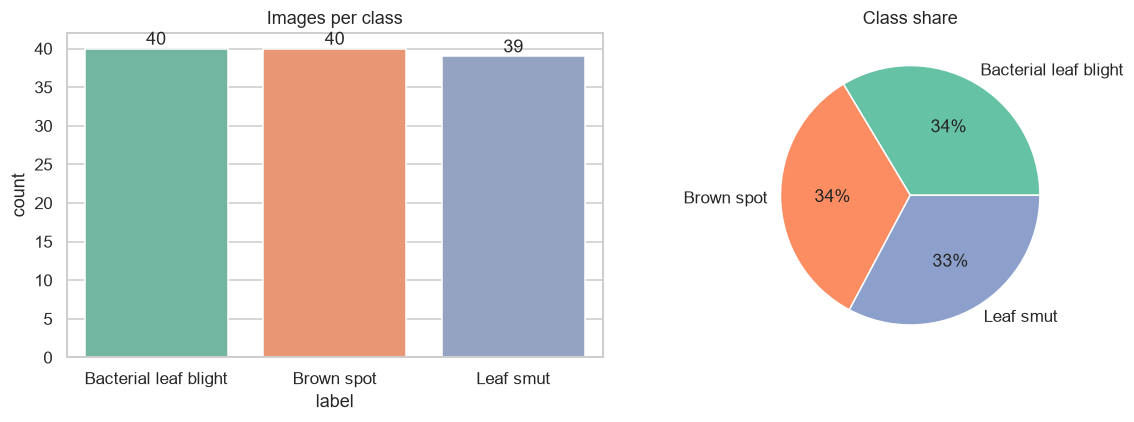

Imbalanced: consider class weights or stratified sampling.


In [6]:
counts = df['label'].value_counts()
print(counts.to_string())

fig, ax = plt.subplots(1, 2, figsize = (11, 4))
sns.countplot(data = df, x = 'label', ax = ax[0], palette = 'Set2')
ax[0].set_title('Images per class')
for c in ax[0].containers:
    ax[0].bar_label(c)
ax[1].pie(counts.values, labels = counts.index, autopct = '%1.0f%%', colors = sns.color_palette('Set2'))
ax[1].set_title('Class share')
plt.tight_layout(); plt.show()
print('Balanced' if counts.nunique() == 1 else 'Imbalanced: consider class weights or stratified sampling.')

## 5. Image properties: size, aspect ratio, format

In [7]:
print(df[['width', 'height' , 'aspect', 'file_kb']].describe().round(2))
print('\nMost common resolutions:')
print(df.groupby(['width', 'height']).size().sort_values(ascending = False).head(10))

         width  height  aspect  file_kb
count   119.00  119.00  119.00   119.00
mean   2383.64  707.74    3.33   307.77
std    1123.53  311.66    0.65   172.70
min     250.00   71.00    1.25    22.76
25%    1074.00  377.00    3.43   102.66
50%    3081.00  897.00    3.43   379.45
75%    3081.00  897.00    3.43   426.88
max    3081.00  900.00    5.30   643.40

Most common resolutions:
width  height
3081   897       85
250    200        2
286    92         1
296    88         1
311    170        1
301    71         1
340    94         1
359    168        1
367    73         1
316    127        1
dtype: int64


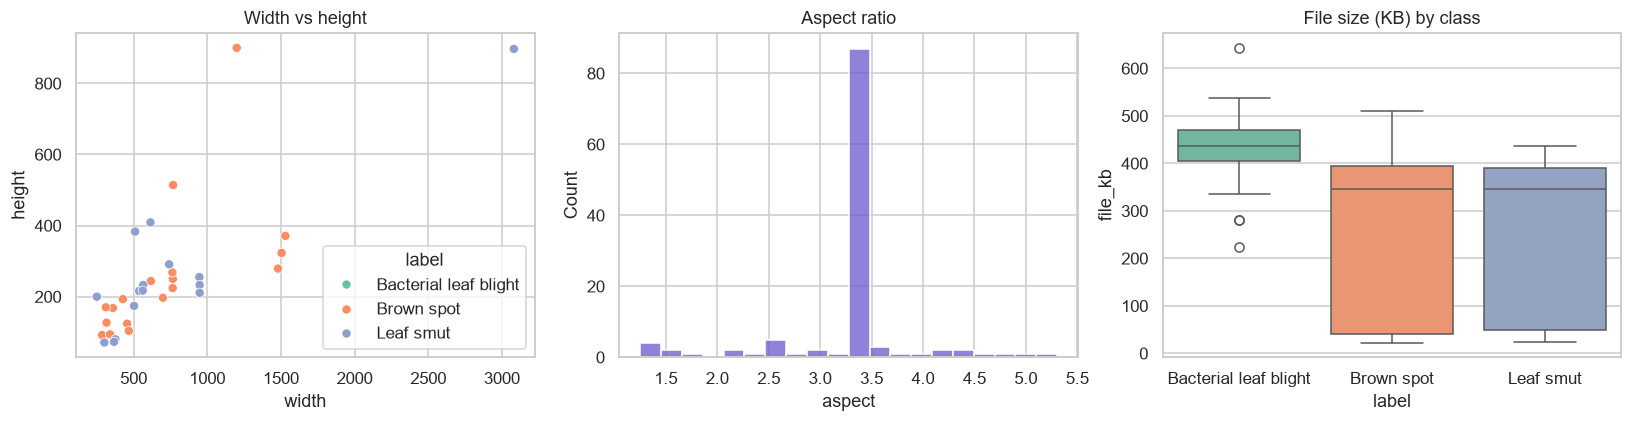

In [8]:
fig, ax = plt.subplots(1, 3, figsize=(15, 4))
sns.scatterplot(data=df, x='width', y='height', hue='label', ax=ax[0], palette='Set2')
ax[0].set_title('Width vs height')
sns.histplot(df['aspect'], bins=20, ax=ax[1], color='slateblue')
ax[1].set_title('Aspect ratio')
sns.boxplot(data=df, x='label', y='file_kb', ax=ax[2], palette='Set2')
ax[2].set_title('File size (KB) by class')
plt.tight_layout(); plt.show()

## 6. Data quality: duplicates

In [9]:
dup = df[df.duplicated('md5', keep = False)].sort_values('md5')
print(f'Exact duplicate images: {len(dup)}')
if len(dup):
    display(dup[['label', 'filename', 'md5']])
    cross = dup.groupby('md5')['label'].nunique()
    print('Duplicates appearing under more than one label:', int((cross > 1).sum()))

Exact duplicate images: 0


## 7. Visual Inspection

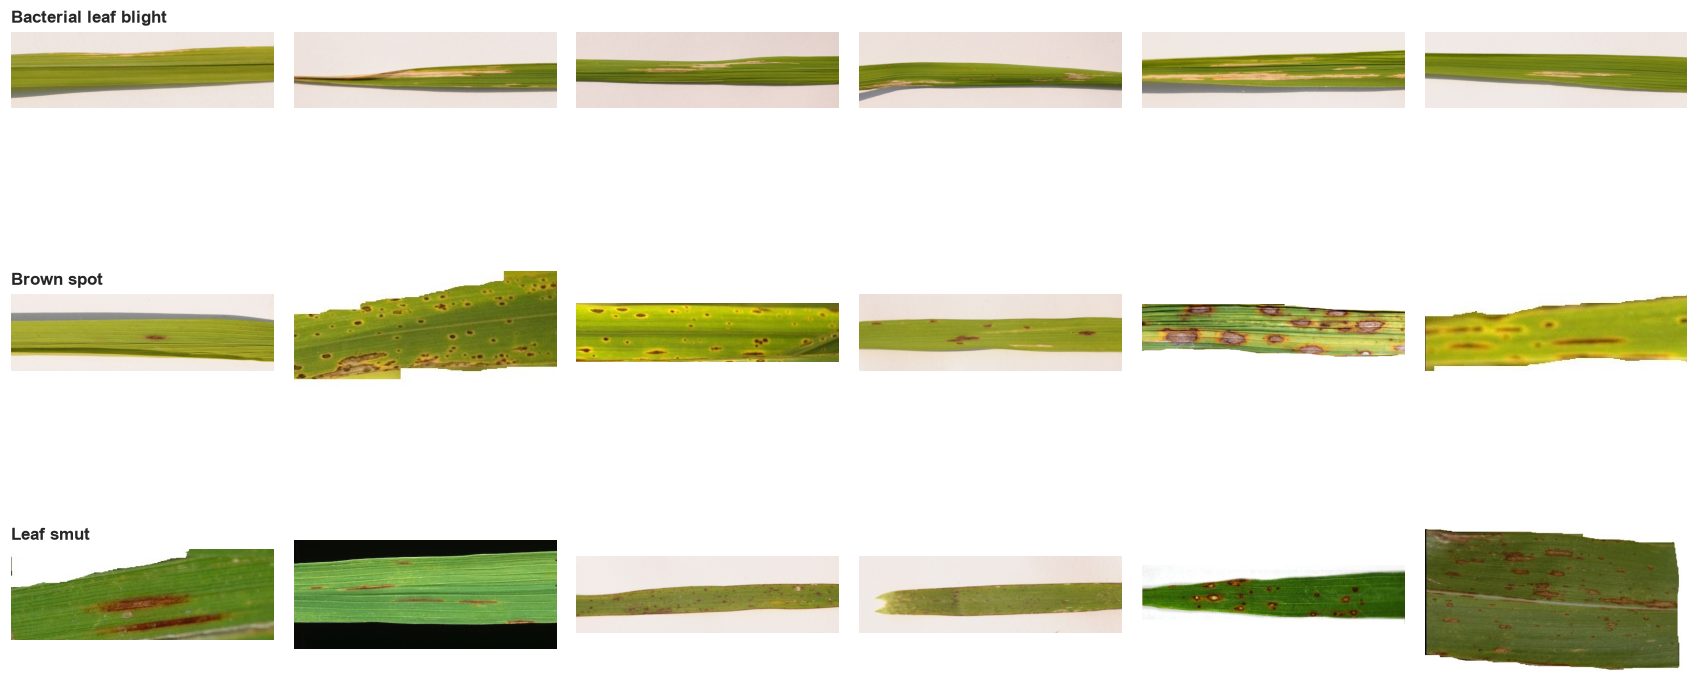

In [10]:
labels = sorted(df['label'].unique())
n = 6
fig, axes = plt.subplots(len(labels), n, figsize = (2.6 * n, 2.8 * len(labels)))
for i, lab in enumerate(labels):
    sample = df[df.label == lab].sample(n, random_state = SEED)
    for j, (_, r)in enumerate(sample.iterrows()):
        ax = axes[i, j]
        ax.imshow(Image.open(r.path).convert('RGB'))
        ax.axis('off')
        if j == 0:
            ax.set_title(lab, loc = 'left', fontsize = 11, fontweight = 'bold')
plt.tight_layout(); plt.show()
    

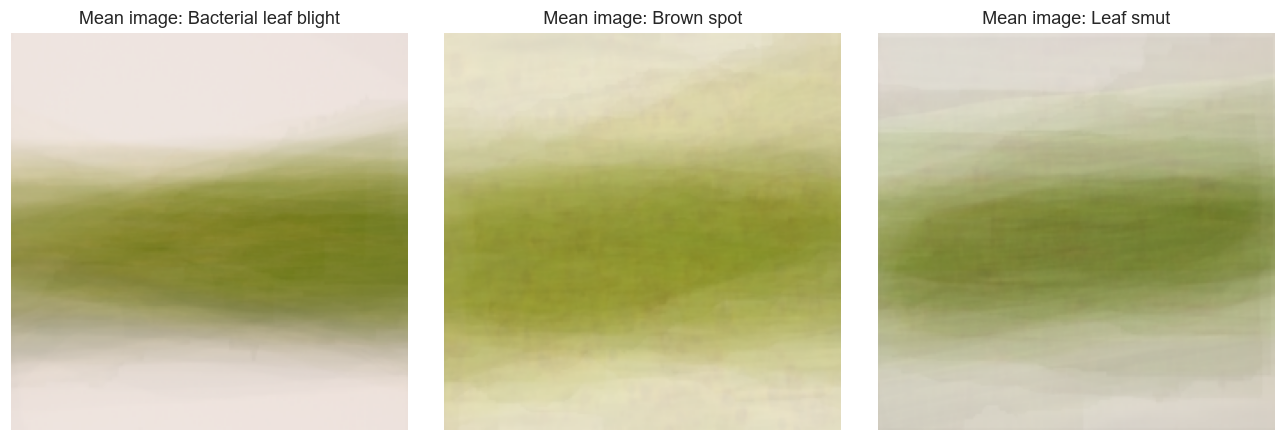

In [11]:
# Average image per class(resized)
SZ = (224, 224)
fig, axes = plt.subplots(1, len(labels), figsize = (4 * len(labels), 4))
for ax, lab in zip(np.atleast_1d(axes), labels):
    stack = np.stack([np.asarray(Image.open(p).convert('RGB').resize(SZ), dtype = np.float32)
                     for p in df[df.label == lab].path])
    ax.imshow(stack.mean(0).astype('uint8')); ax.set_title(f'Mean image: {lab}'); ax.axis('off')
plt.tight_layout(); plt.show()    
    
    

## 8. Color Analysis

                       mean_r  mean_g  mean_b
label                                        
Bacterial leaf blight   194.2   188.9   152.2
Brown spot              191.3   189.5   126.7
Leaf smut               180.1   181.9   141.4


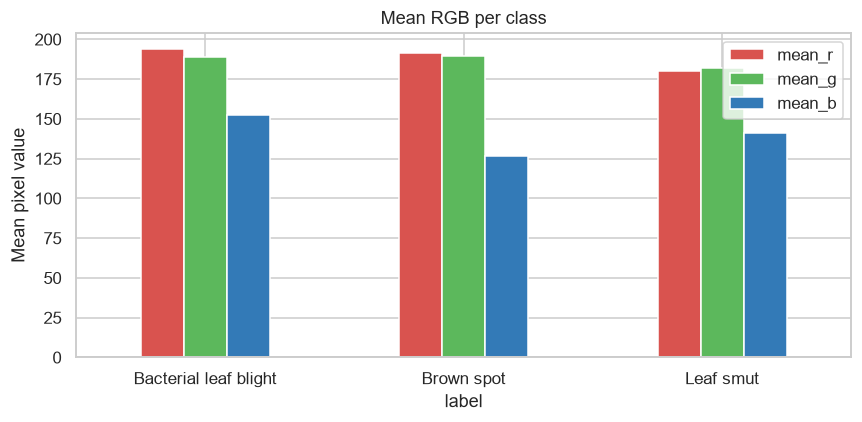

In [12]:
color_means = df.groupby('label')[['mean_r', 'mean_g', 'mean_b']].mean().round(1)
print(color_means)

color_means.plot(kind = 'bar', color = ['#d9534f', '#5cb85c', '#337ab7'], figsize = (8, 4))
plt.title('Mean RGB per class'); plt.ylabel('Mean pixel value'); plt.xticks(rotation = 0)
plt.tight_layout(); plt.show()

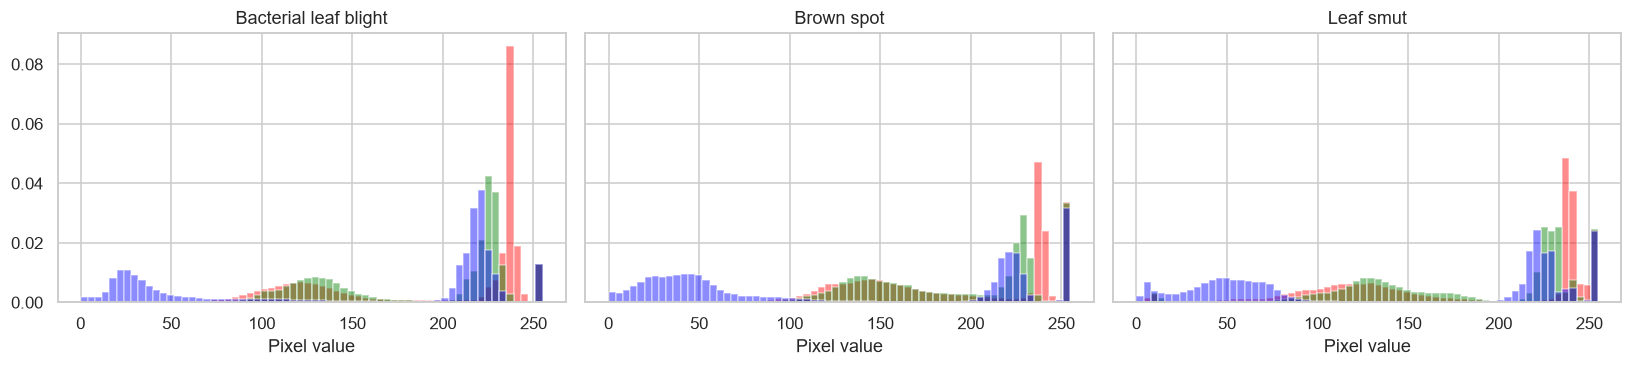

In [13]:
# Per-class RGB histograms (computed on a 128x128 resize for speed)
fig, axes = plt.subplots(1, len(labels), figsize=(5 * len(labels), 3.5), sharey=True)
for ax, lab in zip(np.atleast_1d(axes), labels):
    px = np.concatenate([np.asarray(Image.open(p).convert('RGB').resize((128, 128))).reshape(-1, 3)
                         for p in df[df.label == lab].path])
    for k, col in enumerate(['red', 'green', 'blue']):
        ax.hist(px[:, k], bins=64, range=(0, 255), color=col, alpha=0.45, density=True)
    ax.set_title(lab); ax.set_xlabel('Pixel value')
plt.tight_layout(); plt.show()

## 9. Brightness and Contrast

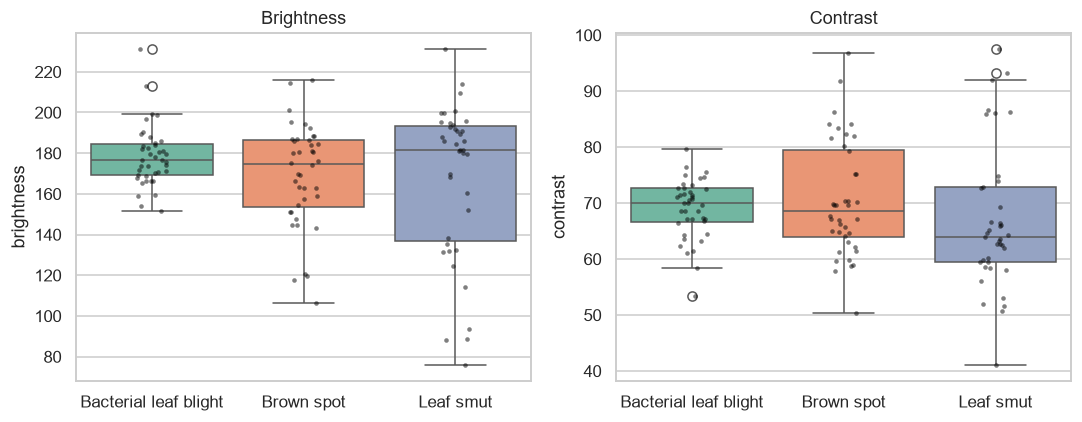

In [14]:
feats = ['brightness', 'contrast']
fig, axes = plt.subplots(1, 2, figsize = (10, 4))
for ax, f in zip(axes, feats):
    sns.boxplot(data = df, x = 'label', y = f, ax = ax, palette = 'Set2')
    sns.stripplot(data = df, x = 'label', y = f, ax = ax, color = 'black', size = 3, alpha =0.5)
    ax.set_title(f.capitalize()); ax.set_xlabel('')
plt.tight_layout(); plt.show()

## 10. Kruskal-Wallis test per feature

In [15]:
test_feats = ['mean_r', 'mean_g', 'mean_b', 'brightness', 'contrast',
              'width', 'height', 'file_kb']
res = []
for f in test_feats:
    groups = [g[f].values for _, g in df.groupby('label')]
    H, p = stats.kruskal(*groups)
    res.append((f, H, p, 'yes' if p < 0.05 else 'no'))
pd.DataFrame(res, columns=['feature', 'H', 'p_value', 'significant (p<0.05)']).round(4)

,feature,H,p_value,significant (p<0.05)
0,mean_r,0.0154,0.9923,no
1,mean_g,1.1814,0.5539,no
2,mean_b,7.1107,0.0286,yes
3,brightness,1.3762,0.5025,no
4,contrast,5.9564,0.0509,no
5,width,23.5376,0.0000,yes
6,height,20.6508,0.0000,yes
7,file_kb,38.9599,0.0000,yes


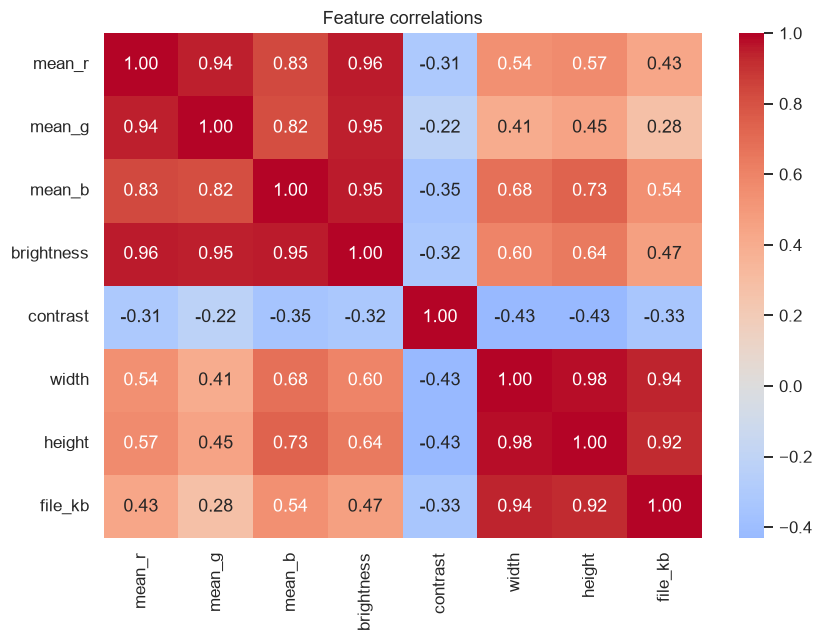

In [16]:
plt.figure(figsize=(8, 6))
sns.heatmap(df[test_feats].corr(), annot=True, fmt='.2f', cmap='coolwarm', center=0)
plt.title('Feature correlations'); plt.tight_layout(); plt.show()

# Key Findings

| Area | Finding | Implication for modeling |
|---|---|---|
| Class balance | 119 images: 40 Bacterial leaf blight, 40 Brown spot, 39 Leaf smut | Nearly balanced; use a stratified split |
| Image size | 85 of 119 are 3081×897; the rest are small and mixed (about 250 to 1500 px wide) | Resize everything to one standard size |
| Aspect ratio | Most images are wide strips (about 3.4:1) | Square resizing distorts leaves; consider padding |
| Duplicates | 0 exact duplicates | No train/test leakage from copies |
| Size and background bias | Width, height and file size differ by class (p < 0.0001); bacterial blight images look uniform, the others vary | Model may learn shortcuts; use background-focused augmentation or cropping |
| Color | Mean blue differs by class (p = 0.029); brightness and mean red/green do not | Color differences may come from backgrounds, so treat them as hints only |
| Sample size | 119 images total | Transfer learning, augmentation, cross-validation |

# Preprocessing

#### Steps: load images, resize to one size, encode labels, split into train / validation / test, save.

## 1. Resize all images to one size

In [17]:
IMG_W, IMG_H = 448, 128  # wide size, close to the 3.4:1 shape

def load_image(path):
    img = Image.open(path).convert('RGB')                             # Open Image
    img = ImageOps.pad(img, (IMG_W, IMG_H), color = (128, 128, 128))  # resize, keep shape, pad with gray 
    return np.asarray(img)                                            # turning into numbers

X = np.array([load_image(p) for p in df['path']])
print('X shape:', X.shape)     

X shape: (119, 128, 448, 3)


## 2. Class names into numbers

In [18]:
le = LabelEncoder()
y = le.fit_transform(df['label'])   # Bacterial = 0, Brown spot = 1, Leaf smut = 2
print(le.classes_)

['Bacterial leaf blight' 'Brown spot' 'Leaf smut']


## 3. Stratified split (70% train, 15% validation, 15% test)

In [19]:
# 70% train, 30% left over
X_train, X_temp, y_train, y_temp = train_test_split(
    X, y, test_size = 0.30, stratify = y, random_state = SEED)

# splitting the leftover in half: 15% validation, 15% test
X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp, test_size = 0.50, stratify = y_temp, random_state = SEED)

# Size and class counts in each split
for name, labels in [('train', y_train), ('val', y_val), ('test', y_test)]:
    print(name, len(labels), 'images, per class:', np.bincount(labels))

train 83 images, per class: [28 28 27]
val 18 images, per class: [6 6 6]
test 18 images, per class: [6 6 6]


## 4. Checking one image per class

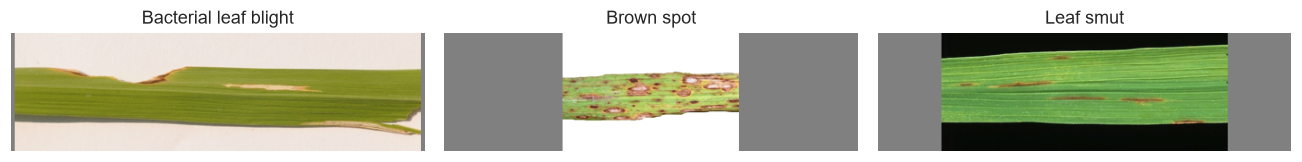

In [20]:
# One preprocessed image per class
fig, axes = plt .subplots(1, 3, figsize = (12, 3))
for k,  ax in enumerate(axes):
    ax.imshow(X_train[y_train == k][0])
    ax.set_title(le.classes_[k])
    ax.axis('off')
plt.tight_layout(); plt.show()

# Model Building

## 1. Model

In [21]:
model = keras.Sequential([layers.Input(shape = (128, 448, 3)), layers.Rescaling(1./255),
                          
                          layers.Conv2D(16, 3, activation = 'relu'), 
                          layers.MaxPooling2D(),
                           
                          layers.Conv2D(32, 3, activation = 'relu'),
                          layers.MaxPooling2D(),

                          layers.Conv2D(64, 3, activation = 'relu'),
                          layers.MaxPooling2D(),

                          layers.Conv2D(128, 3, activation = 'relu'),
                          layers.MaxPooling2D(),

                          layers.GlobalAveragePooling2D(),
                          layers.Dense(64, activation = 'relu'),
                          layers.Dense(3, activation = 'softmax'),
                         ])
model.compile(optimizer = 'adam',
             loss = 'sparse_categorical_crossentropy',
             metrics = ['accuracy'])
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ rescaling (Rescaling)                │ (None, 128, 448, 3)         │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d (Conv2D)                      │ (None, 126, 446, 16)        │             448 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d (MaxPooling2D)         │ (None, 63, 223, 16)         │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_1 (Conv2D)                    │ (None, 61, 221, 32)         │           4,640 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_1 (MaxPooling2D)       │ (None, 30, 110, 32)         │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_2 (Conv2D)                    │ (None, 28, 108, 64)         │          18,496 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_2 (MaxPooling2D)       │ (None, 14, 54, 64)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_3 (Conv2D)                    │ (None, 12, 52, 128)         │          73,856 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_3 (MaxPooling2D)       │ (None, 6, 26, 128)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ global_average_pooling2d             │ (None, 128)                 │               0 │
│ (GlobalAveragePooling2D)             │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense (Dense)                        │ (None, 64)                  │           8,256 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_1 (Dense)                      │ (None, 3)                   │             195 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 105,891 (413.64 KB)

 Trainable params: 105,891 (413.64 KB)

 Non-trainable params: 0 (0.00 B)

## 2. Train

In [22]:
early_stop = keras.callbacks.EarlyStopping(
    monitor = 'val_loss', patience = 5, restore_best_weights = True)

history = model.fit(
    X_train, y_train,
    validation_data = (X_val, y_val),
    epochs = 30,
    batch_size = 16,
    callbacks = [early_stop])

Epoch 1/30
6/6 ━━━━━━━━━━━━━━━━━━━━ 3s 316ms/step - accuracy: 0.3373 - loss: 1.1136 - val_accuracy: 0.3333 - val_loss: 1.0986
Epoch 2/30
6/6 ━━━━━━━━━━━━━━━━━━━━ 1s 130ms/step - accuracy: 0.3373 - loss: 1.0977 - val_accuracy: 0.3333 - val_loss: 1.0969
Epoch 3/30
6/6 ━━━━━━━━━━━━━━━━━━━━ 1s 134ms/step - accuracy: 0.3373 - loss: 1.0970 - val_accuracy: 0.4444 - val_loss: 1.0941
Epoch 4/30
6/6 ━━━━━━━━━━━━━━━━━━━━ 1s 132ms/step - accuracy: 0.3855 - loss: 1.0954 - val_accuracy: 0.4444 - val_loss: 1.0884
Epoch 5/30
6/6 ━━━━━━━━━━━━━━━━━━━━ 1s 132ms/step - accuracy: 0.3976 - loss: 1.0914 - val_accuracy: 0.4444 - val_loss: 1.0765
Epoch 6/30
6/6 ━━━━━━━━━━━━━━━━━━━━ 1s 132ms/step - accuracy: 0.4217 - loss: 1.0827 - val_accuracy: 0.5000 - val_loss: 1.0555
Epoch 7/30
6/6 ━━━━━━━━━━━━━━━━━━━━ 1s 132ms/step - accuracy: 0.4217 - loss: 1.0666 - val_accuracy: 0.4444 - val_loss: 1.0113
Epoch 8/30
6/6 ━━━━━━━━━━━━━━━━━━━━ 1s 134ms/step - accuracy: 0.4337 - loss: 1.0373 - val_accuracy: 0.5556 - val_loss:

## 3. Plotting the learning curve

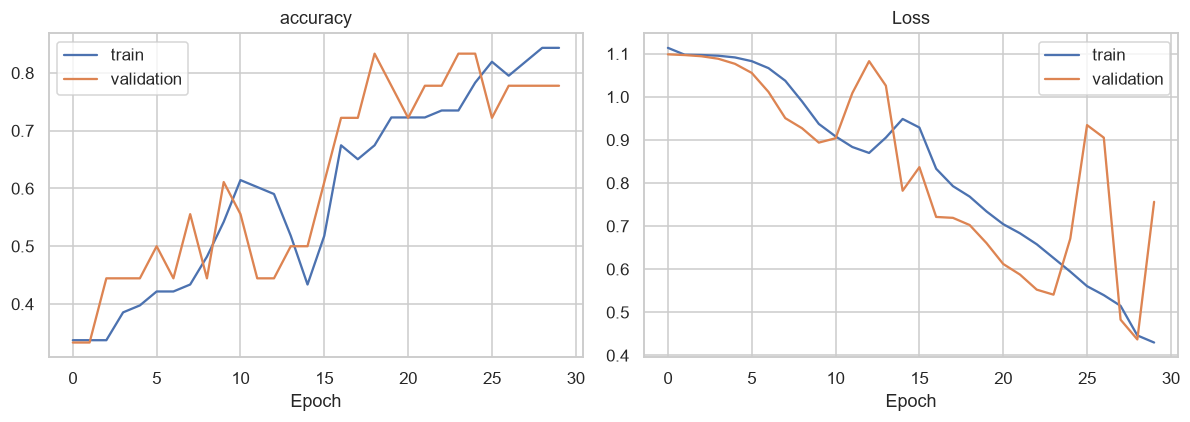

In [23]:
fig, ax = plt.subplots(1, 2, figsize = (11, 4))

ax[0].plot(history.history['accuracy'], label = 'train')
ax[0].plot(history.history['val_accuracy'], label = 'validation')
ax[0].set_title('accuracy'); ax[0].set_xlabel('Epoch'); ax[0].legend()

ax[1].plot(history.history['loss'], label = 'train')
ax[1].plot(history.history['val_loss'], label = 'validation')
ax[1].set_title('Loss'); ax[1].set_xlabel('Epoch'); ax[1].legend()

plt.tight_layout(); plt.show()


## 4. Evaluate on the validation set

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 152ms/step
                       precision    recall  f1-score   support

Bacterial leaf blight       1.00      0.83      0.91         6
           Brown spot       0.60      1.00      0.75         6
            Leaf smut       1.00      0.50      0.67         6

             accuracy                           0.78        18
            macro avg       0.87      0.78      0.78        18
         weighted avg       0.87      0.78      0.78        18



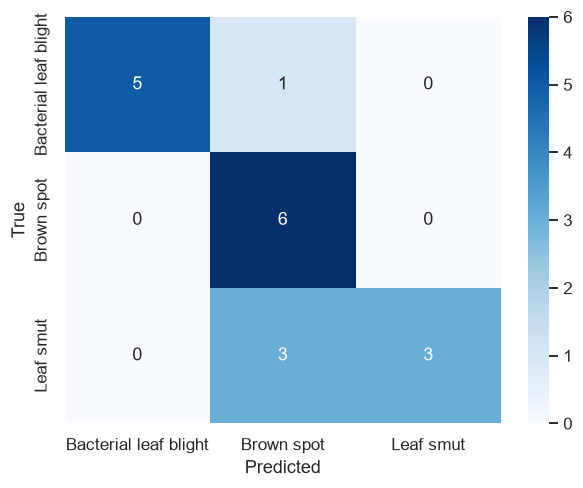

In [24]:
# predicted class = one with the highest probability
y_pred = model.predict(X_val).argmax(axis = 1)

print(classification_report(y_val, y_pred, target_names = le.classes_))

# confusion matrix: rows = true class, columns = predicted class
cm = confusion_matrix(y_val, y_pred)
sns.heatmap(cm, annot = True, fmt = 'd', cmap = 'Blues',
            xticklabels = le.classes_, yticklabels = le.classes_)
plt.xlabel('Predicted'); plt.ylabel('True'); plt.show()

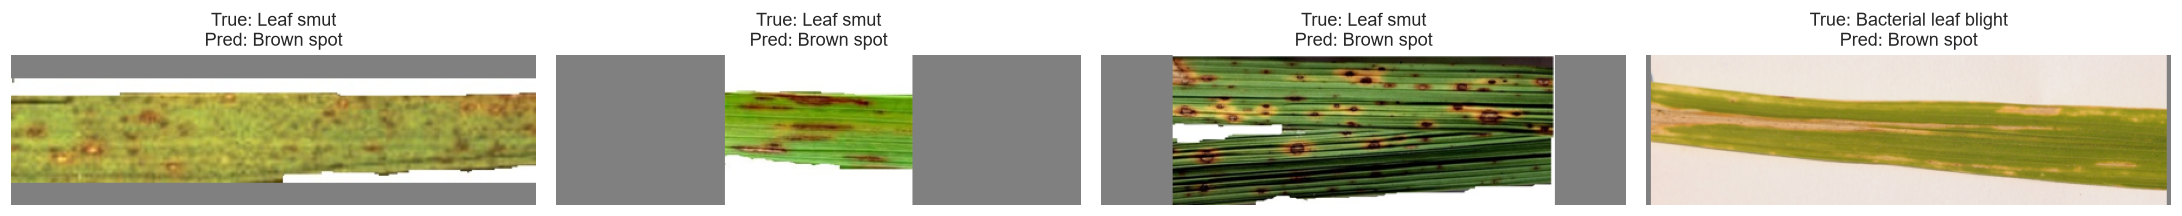

In [25]:
# positions of the wrong predictions
wrong = np.where(y_pred != y_val)[0]

# showing each wrong image with its true and predicted class
fig, axes = plt.subplots(1, len(wrong), figsize=(5 * len(wrong), 3))
for ax, i in zip(axes, wrong):
    ax.imshow(X_val[i])
    ax.set_title(f'True: {le.classes_[y_val[i]]}\nPred: {le.classes_[y_pred[i]]}')
    ax.axis('off')
plt.tight_layout(); plt.show()

## Baseline CNN — Summary

My own small CNN (4 convolution blocks) is the starting point for comparison. A single training run scored between 72% and 83% on the validation set depending on the random seed. That is a big swing, and it comes from the validation set having only 18 images. So I use the average of 3 runs (0.87, from the augmentation experiment) as the baseline score in the rest of the notebook.

The misclassified images show a few possible causes: leaves with very faint symptoms, lesions that look similar across diseases, and odd crops with gray padding.

# Data Augmentations

## 1. Preview the Augmentation
#### Augmentations only change the training images. The validation set stays untouched.

In [26]:
def get_aug(name):
    # geometric: flips, small rotation, zoom, shift
    geometric = [layers.RandomFlip('horizontal_and_vertical'),
                 layers.RandomRotation(0.05),
                 layers.RandomZoom(0.1),
                 layers.RandomTranslation(0.05, 0.05)]
    # photometric: pixels are now 0-1, so tell brightness the range
    photometric = [layers.RandomBrightness(0.2, value_range=(0, 1)),
                   layers.RandomContrast(0.2)]
    # noise: 0.04 on a 0-1 scale is the same as 10 on a 0-255 scale
    noise = [layers.GaussianNoise(0.04)]

    options = {'none': [],
               'geometric': geometric,
               'photometric': photometric,
               'noise': noise,
               'all combined': geometric + photometric + noise}
    return options[name]

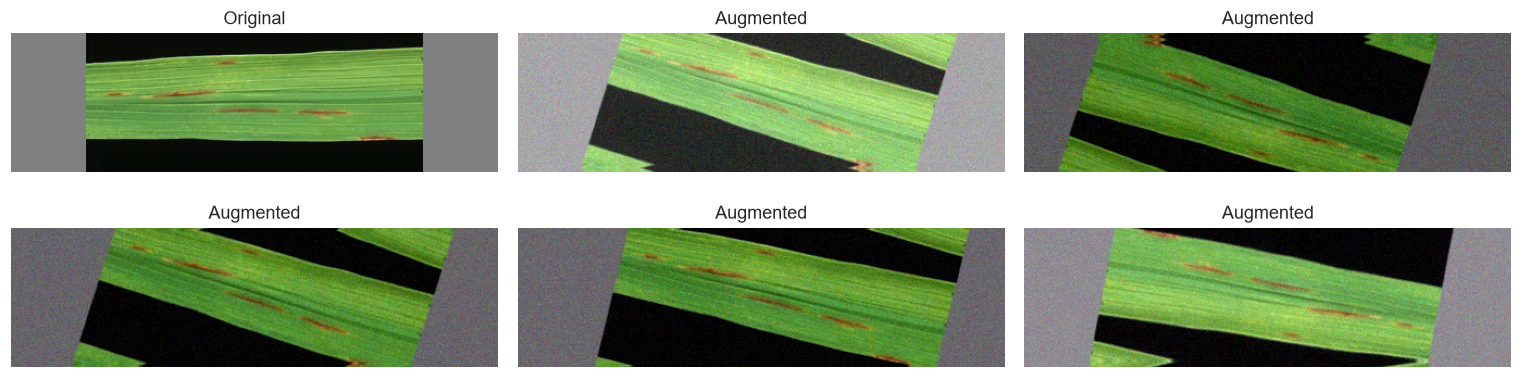

In [27]:
# showing the original and 5 random augmented version of one image
# Rescaling comes first, so augmentations work on 0-1 pixels

aug = keras.Sequential([layers.Rescaling(1./255)] + get_aug('all combined'))
img = X_train[:1].astype('float32')

fig, axes = plt.subplots(2, 3, figsize=(14, 4))
for k, ax in enumerate(axes.flat):
    if k == 0:
        ax.imshow(X_train[0]); ax.set_title('Original')
    else:
        ax.imshow(aug(img, training=True)[0].numpy().clip(0, 1))
        ax.set_title('Augmented')
    ax.axis('off')
plt.tight_layout(); plt.show()

## 2. Model Builder

In [28]:
def make_model(aug_layers):
    model = keras.Sequential(
        [layers.Input(shape = (128, 448, 3)),
         layers.Rescaling(1./255)]
        + aug_layers
        + [layers.Conv2D(16, 3, activation = 'relu'), layers.MaxPooling2D(),
           layers.Conv2D(32, 3, activation = 'relu'), layers.MaxPooling2D(),
           layers.Conv2D(64, 3, activation = 'relu'), layers.MaxPooling2D(),
           layers.Conv2D(128, 3, activation = 'relu'), layers.MaxPooling2D(),
           layers.GlobalAveragePooling2D(),
           layers.Dense(64, activation = 'relu'),
           layers.Dense(3, activation = 'softmax')])
    model.compile(optimizer = 'adam',
                 loss = 'sparse_categorical_crossentropy',
                 metrics = ['accuracy'])
    return model

## 3. Comparison

In [29]:
N_RUNS = 3        
results = []
histories = {}    

for name in ['none', 'geometric', 'photometric', 'noise', 'all combined']:
    accs = []
    for run in range(N_RUNS):
        keras.backend.clear_session()  
        tf.keras.utils.set_random_seed(run)             # different seed each run
        model = make_model(get_aug(name))
        stop = keras.callbacks.EarlyStopping(
            monitor='val_loss', patience=8, restore_best_weights=True)
        hist = model.fit(X_train, y_train,
                         validation_data=(X_val, y_val),
                         epochs=40, batch_size=16,
                         callbacks=[stop], verbose=0)
        loss, acc = model.evaluate(X_val, y_val, verbose=0)   # score with best weights
        accs.append(acc)
        if run == 0:
            histories[name] = hist.history
    results.append({'augmentation': name,
                    'mean_val_acc': round(np.mean(accs), 3),
                    'std': round(np.std(accs), 3)})
    print(name, 'done:', round(np.mean(accs), 3))

results_df = pd.DataFrame(results)
results_df

none done: 0.87
geometric done: 0.778
photometric done: 0.759
noise done: 0.833
all combined done: 0.704


,augmentation,mean_val_acc,std
0,none,0.870,0.026
1,geometric,0.778,0.091
2,photometric,0.759,0.094
3,noise,0.833,0.045
4,all combined,0.704,0.026


## 4. Plotting the results

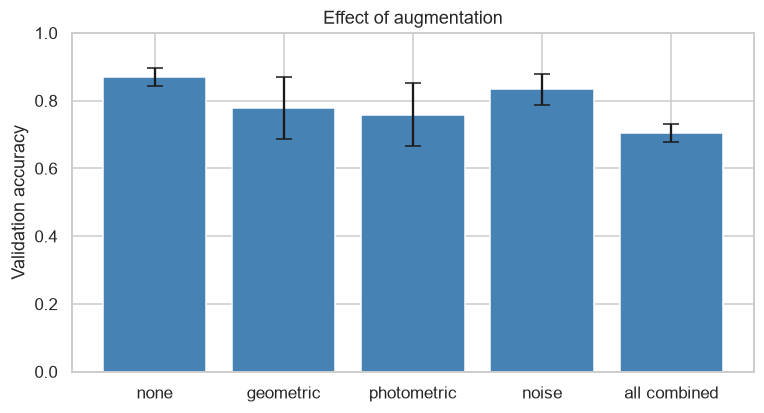

In [30]:
plt.figure(figsize = (8, 4))
plt.bar(results_df['augmentation'], results_df['mean_val_acc'],
       yerr = results_df['std'], capsize = 5, color = 'steelblue')
plt.ylabel('Validation accuracy'); plt.title('Effect of augmentation')
plt.ylim(0, 1); plt.show()


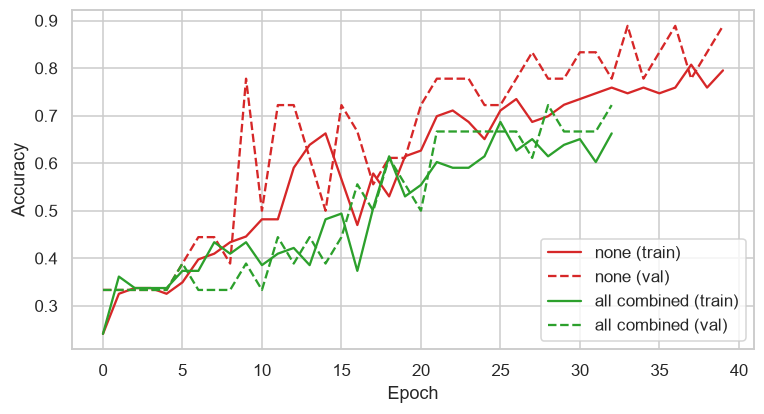

In [31]:
# learning curves: no augmentation vs all combined
plt.figure(figsize = (8, 4))
for name, color in [('none', 'tab:red'), ('all combined', 'tab:green')]:
    plt.plot(histories[name]['accuracy'], color = color, label = f'{name} (train)')
    plt.plot(histories[name]['val_accuracy'], color = color, linestyle = '--', label = f'{name} (val)')
plt.xlabel('Epoch'); plt.ylabel('Accuracy'); plt.legend(); plt.show()    

## Augmentation Study — Results

I wanted to see if changing the training images (flips, rotations, brightness, noise) would help the model. I trained the same CNN five ways, three times each with different random seeds, and averaged the accuracy on the validation set.

| Augmentation | Mean val accuracy | Std |
|---|---|---|
| None | 0.870 | 0.026 |
| Noise | 0.833 | 0.045 |
| Geometric | 0.778 | 0.091 |
| Photometric | 0.759 | 0.094 |
| All combined | 0.704 | 0.026 |

**What I found**
- Training with no augmentation did best. None of the augmentations improved the model.
- Noise came close to no augmentation, but the gap was smaller than the difference between runs, so I can't say it was really worse.
- Using everything together gave the lowest score.
- The validation set only has 18 images, so one image changes accuracy by about 5.5%. Small differences between options shouldn't be trusted too much.

**Why this might have happened**
- The disease spots are small and color matters, so zooming, rotating or changing brightness may hide or blur them.
- Augmented images are harder, so the model may need more training time.
- A small CNN trained from scratch may not benefit much from augmentation.

# Transfer Learning with MobileNetV2 and EfficientNetB0

I used pretrained models (MobileNetV2 and EfficientNetB0) that already learned from millions of images, and trained them on the rice leaf images in two stages: first only the new last layer, then a gentle fine-tuning of the top layers. I also tested gentle augmentation again.

## 1. Model

In [32]:
def build_model(base_name , use_aug):
    # loading the pretrained model without its original classifier
    if base_name == 'MobileNetV2':
        base = MobileNetV2(include_top = False, weights = 'imagenet', input_shape = (128, 448, 3))
    else:
        base = EfficientNetB0(include_top = False, weights = 'imagenet', input_shape = (128, 448, 3))
    base.trainable = False

    input = keras.Input(shape = (128, 448, 3))
    x = input
    if use_aug:
        x = layers.RandomFlip('horizontal')(x)
        x = layers.RandomRotation(0.02)(x)
        x = layers.RandomZoom(0.05)(x)
    if base_name == 'MobileNetV2':
        x = layers.Rescaling(1/127.5, offset = -1)(x)
    x = base(x, training = False)
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dropout(0.3)(x)
    output = layers.Dense(3, activation = 'softmax')(x)
    return keras.Model(input, output), base

## 2. Training in two stages

In [33]:
def train_model(base_name, use_aug, seed):
    keras.backend.clear_session()
    tf.keras.utils.set_random_seed(seed)
    model, base = build_model(base_name, use_aug)

    # stage 1: training only new last layer
    model.compile(optimizer = keras.optimizers.Adam(1e-3),
                  loss = 'sparse_categorical_crossentropy', metrics = ['accuracy'])
    stop = keras.callbacks.EarlyStopping(monitor = 'val_loss', patience = 5, restore_best_weights = True)
    model.fit(X_train, y_train, validation_data = (X_val, y_val),
             epochs = 20, batch_size = 16, callbacks = [stop], verbose = 0)

    # Stage 2: unfreezing the last 20 layers of the base and train gently
    base.trainable = True
    for layer in base.layers[:-20]:
        layer.trainable = False
    model.compile(optimizer=keras.optimizers.Adam(1e-5),     
                  loss='sparse_categorical_crossentropy', metrics=['accuracy'])
    stop = keras.callbacks.EarlyStopping(monitor='val_loss', patience=5, restore_best_weights=True)
    model.fit(X_train, y_train, validation_data = (X_val, y_val),
             epochs = 20, batch_size = 16, callbacks = [stop], verbose = 0)

    loss, acc = model.evaluate(X_val, y_val, verbose = 0)
    return model, acc

## 3. The Comparison

In [34]:
N_RUNS = 3
results = []
for base_name in ['MobileNetV2', 'EfficientNetB0']:
    for use_aug in [False, True]:
        accs = []
        start = time.time()
        for run in range(N_RUNS):
            model, acc = train_model(base_name, use_aug, run)
            accs.append(acc)
        aug_name = 'gentle' if use_aug else 'none'
        model.save(f'{base_name}_{aug_name}.keras')
        results.append({'model': base_name,
                        'augmentation': aug_name,
                        'mean_val_acc': round(np.mean(accs), 3),
                        'std': round(np.std(accs), 3),
                        'params': model.count_params(),
                        'minutes': round((time.time() - start) / 60, 1)})
        print(base_name, aug_name, 'done:', round(np.mean(accs), 3))

results_df = pd.DataFrame(results)

MobileNetV2 none done: 0.981
MobileNetV2 gentle done: 0.981
EfficientNetB0 none done: 0.907
EfficientNetB0 gentle done: 0.926


In [35]:
results_df

,model,augmentation,mean_val_acc,std,params,minutes
0,MobileNetV2,none,0.981,0.026,2261827,4.8
1,MobileNetV2,gentle,0.981,0.026,2261827,5.7
2,EfficientNetB0,none,0.907,0.026,4053414,7.8
3,EfficientNetB0,gentle,0.926,0.026,4053414,10.1


## 4. Plot

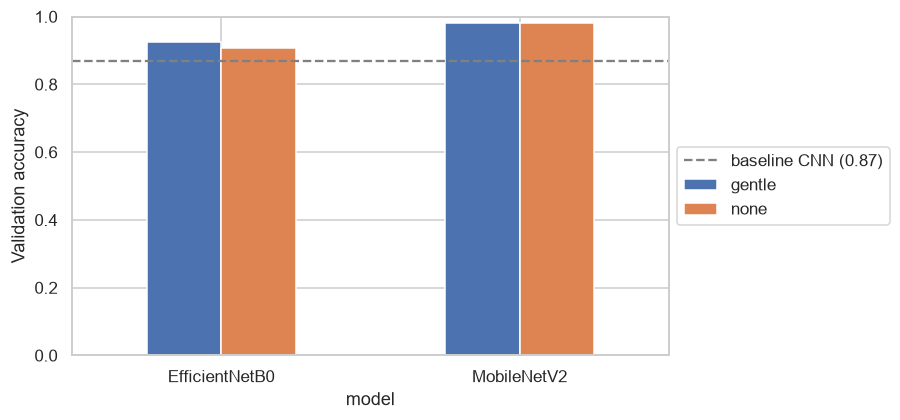

In [36]:
# comparing models and augmentation side by side
results_df.pivot(index = 'model', columns = 'augmentation', values = 'mean_val_acc').plot(
    kind = 'bar', ylim = (0, 1), rot = 0, figsize = (7, 4))
plt.axhline(0.87, color = 'gray', linestyle = '--', label = 'baseline CNN (0.87)')
plt.ylabel('Validation accuracy'); plt.legend(loc='center left', bbox_to_anchor=(1, 0.5)); plt.show()

## Transfer Learning — Results

I trained two pretrained models, MobileNetV2 and EfficientNetB0, in two stages: first only the new last layer, then a gentle fine-tuning of the top 20 layers. Each was trained 3 times, with and without gentle augmentation (small flip, rotation and zoom).

| Model | Augmentation | Mean val accuracy | Std | Parameters | Training time (3 runs) |
|---|---|---|---|---|---|
| MobileNetV2 | none | 0.981 | 0.026 | 2.26M | 4.8 min |
| MobileNetV2 | gentle | 0.981 | 0.026 | 2.26M | 5.7 min |
| EfficientNetB0 | none | 0.907 | 0.026 | 4.05M | 7.8 min |
| EfficientNetB0 | gentle | 0.926 | 0.026 | 4.05M | 10.1 min |

**What I found**
- Both pretrained models beat my own CNN (0.87 in the augmentation experiment). MobileNetV2 reached about 0.98.
- MobileNetV2 did better than EfficientNetB0, and it is smaller and faster to train.
- Gentle augmentation did not change much. The small difference for EfficientNetB0 is less than one validation image, so I can't call it a real improvement. Unlike the strong augmentations earlier, it also did not hurt.

**Caution**
- The validation set only has 18 images, so one image is about 5.5%, and the std of 0.026 is about one image.
- These scores are a bit optimistic because the validation set was also used to stop training early. I will check the models on the untouched test set next.

# Model Comparison on the Test Set

I scored all four saved models (MobileNetV2 and EfficientNetB0, with and without gentle augmentation) on the test set, which none of them had seen before. I compared accuracy, precision, recall, F1, model size and prediction speed to choose a model for production.

## 1. Scoring all models on the test set

In [37]:
model_files = ['MobileNetV2_none.keras', 'MobileNetV2_gentle.keras',
               'EfficientNetB0_none.keras', 'EfficientNetB0_gentle.keras']

test_results = []
test_preds = {}

for file in model_files:
    m = keras.models.load_model(file)

    m.predict(X_test[:1], verbose = 0)
    start = time.time()
    probs = m.predict(X_test, verbose = 0)
    ms_per_image = (time.time() - start) / len(X_test) * 1000

    y_pred_test = probs.argmax(axis = 1)
    test_preds[file] = y_pred_test

    p, r, f1, _ = precision_recall_fscore_support(
        y_test, y_pred_test, average = 'macro', zero_division = 0)

    test_results.append({'model': file.replace('.keras', ''),
                         'test_acc': round(accuracy_score(y_test, y_pred_test), 3),
                         'precision': round(p, 3),
                         'recall': round(r, 3),
                         'f1': round(f1, 3),
                         'params': m.count_params(),
                         'size_mb': round(os.path.getsize(file) / 1e6, 1),
                         'ms_per_image': round(ms_per_image, 1)})
test_df = pd.DataFrame(test_results)
test_df
    

,model,test_acc,precision,recall,f1,params,size_mb,ms_per_image
0,MobileNetV2_none,0.722,0.756,0.722,0.715,2261827,19.3,100.7
1,MobileNetV2_gentle,0.722,0.736,0.722,0.716,2261827,19.3,96.0
2,EfficientNetB0_none,0.778,0.827,0.778,0.768,4053414,27.9,167.7
3,EfficientNetB0_gentle,0.778,0.783,0.778,0.777,4053414,27.9,265.4


## Test Set Results

I scored the four saved models on the test set (18 images that were never used for training or early stopping).

| Model | Test accuracy | Precision | Recall | F1 | Parameters | Size | Time per image |
|---|---|---|---|---|---|---|---|
| MobileNetV2 (none) | 0.722 | 0.756 | 0.722 | 0.715 | 2.26M | 19.3 MB |  100.7 ms |
| MobileNetV2 (gentle) | 0.722 | 0.736 | 0.722 | 0.716 | 2.26M | 19.3 MB |  96.0 ms |
| EfficientNetB0 (none) | 0.778 | 0.827 | 0.778 | 0.768 | 4.05M | 27.9 MB |  167.7 ms |
| EfficientNetB0 (gentle) | 0.778 | 0.783 | 0.778 | 0.777 | 4.05M | 27.9 MB |  265.4 ms |

**What I found**
- Test accuracy was much lower than validation accuracy (about 0.72 to 0.78 compared with 0.91 to 0.98). The validation set was used to stop training, so those scores were too optimistic.
- The models are close. MobileNetV2 got 13 of 18 images right and EfficientNetB0 got 14 of 18, a difference of one image, so I can't say one is clearly better.
- Gentle augmentation made no difference.
- MobileNetV2 is about 30% smaller and faster per image (about 100 ms vs 170 ms or more on my CPU).
- Brown spot was the hardest class (recall 0.50 for MobileNetV2).

**Limits**
- With only 18 test images, one image is 5.5% accuracy, so these scores are rough estimates.
- Timing was measured on my own machine's CPU and will differ on other hardware.

## 2. Confusion Matrices

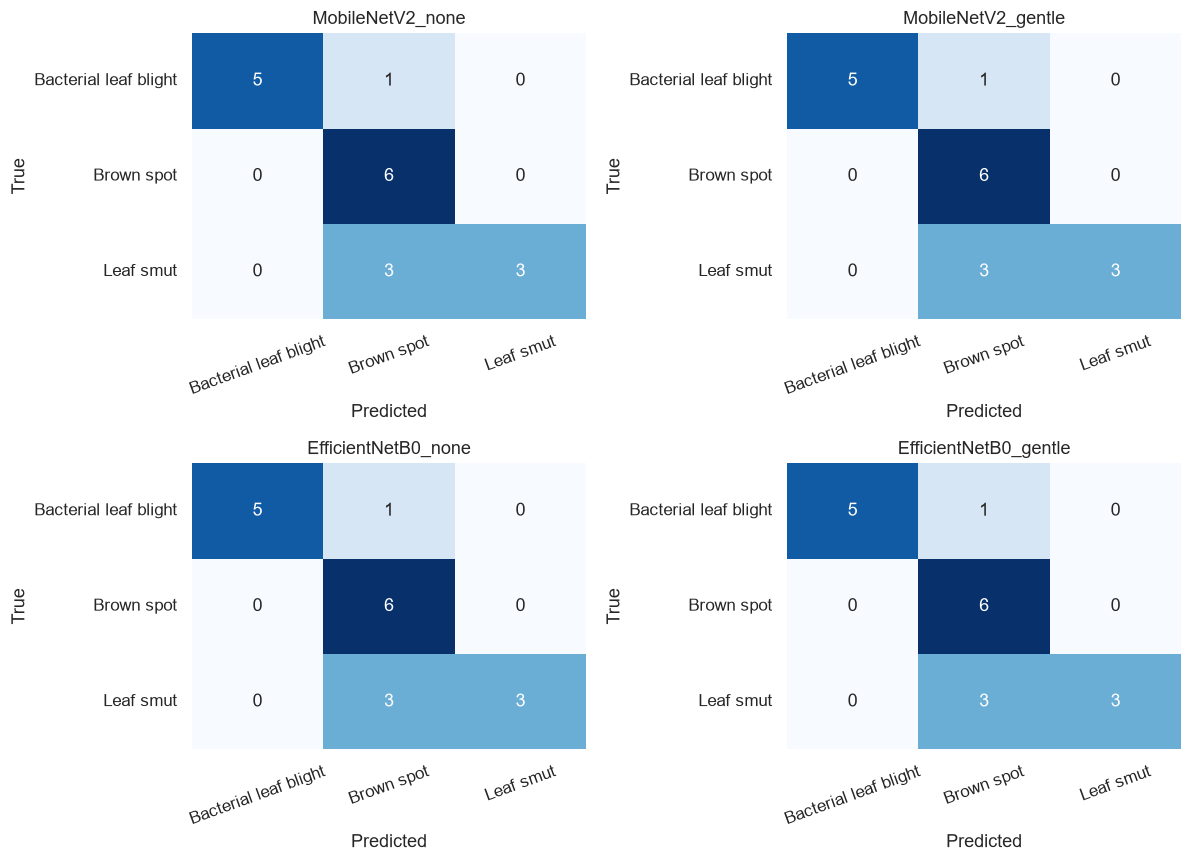

In [38]:
fig, axes = plt.subplots(2, 2, figsize = (11, 8))
for ax, file in zip(axes.flat, model_files):
    sm = confusion_matrix(y_test, test_preds[file])
    sns.heatmap(cm, annot = True, fmt = 'd', cmap = 'Blues', cbar = False, ax = ax,
                xticklabels = le.classes_, yticklabels = le.classes_)
    ax.set_title(file.replace('.keras', ''))
    ax.set_xlabel('Predicted'); ax.set_ylabel('True')
    ax.tick_params(axis = 'x', rotation = 20)
plt.tight_layout(); plt.show()

## 3. Per-class report for the model 

In [39]:
chosen = 'MobileNetV2_none.keras'    # change this to the model you want to look at
print(classification_report(y_test, test_preds[chosen], target_names=le.classes_))

                       precision    recall  f1-score   support

Bacterial leaf blight       0.67      1.00      0.80         6
           Brown spot       0.60      0.50      0.55         6
            Leaf smut       1.00      0.67      0.80         6

             accuracy                           0.72        18
            macro avg       0.76      0.72      0.72        18
         weighted avg       0.76      0.72      0.72        18



## 4. Plot test accuracy

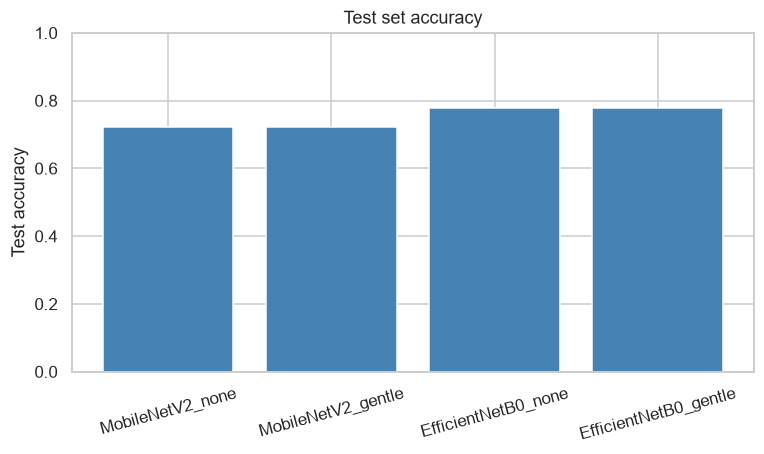

In [40]:
plt.figure(figsize = (8, 4))
plt.bar(test_df['model'], test_df['test_acc'], color = 'steelblue')
plt.ylim(0, 1); plt.ylabel('Test accuracy')
plt.xticks(rotation = 15); plt.title('Test set accuracy'); plt.show()

# Cross-Validation

The test set only has 18 images, so I used 5-fold cross-validation on all 119 images to get a more reliable comparison of MobileNetV2 and EfficientNetB0.

## 1. Training function

In [41]:
def train_on(base_name, X_tr, y_tr, X_va, y_va, seed):
    keras.backend.clear_session()
    tf.keras.utils.set_random_seed(seed)
    model, base = build_model(base_name, False)        # no augmentation

    # stage 1: train only the new last layer
    model.compile(optimizer=keras.optimizers.Adam(1e-3),
                  loss='sparse_categorical_crossentropy', metrics=['accuracy'])
    stop = keras.callbacks.EarlyStopping(monitor='val_loss', patience=5, restore_best_weights=True)
    model.fit(X_tr, y_tr, validation_data=(X_va, y_va),
              epochs=20, batch_size=16, callbacks=[stop], verbose=0)

    # stage 2: unfreeze the last 20 layers and train gently
    base.trainable = True
    for layer in base.layers[:-20]:
        layer.trainable = False
    model.compile(optimizer=keras.optimizers.Adam(1e-5),
                  loss='sparse_categorical_crossentropy', metrics=['accuracy'])
    stop = keras.callbacks.EarlyStopping(monitor='val_loss', patience=5, restore_best_weights=True)
    model.fit(X_tr, y_tr, validation_data=(X_va, y_va),
              epochs=20, batch_size=16, callbacks=[stop], verbose=0)
    return model

## 2. Running the cross-validation

In [42]:
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)   # 5 groups, same class mix
cv_rows = []
cv_preds = {}                                                         # for the confusion matrices

for base_name in ['MobileNetV2', 'EfficientNetB0']:
    fold_accs, all_true, all_pred = [], [], []

    for fold, (train_idx, test_idx) in enumerate(skf.split(X, y)):
        X_tr, y_tr = X[train_idx], y[train_idx]          # 4 groups to train on
        X_te, y_te = X[test_idx], y[test_idx]            # 1 group to test on

        # take a small part of the training data for early stopping only
        X_tr, X_va, y_tr, y_va = train_test_split(
            X_tr, y_tr, test_size=0.15, stratify=y_tr, random_state=SEED)

        model = train_on(base_name, X_tr, y_tr, X_va, y_va, seed=fold)

        pred = model.predict(X_te, verbose=0).argmax(axis=1)
        acc = (pred == y_te).mean()                      # accuracy on the held-out group
        fold_accs.append(acc)
        all_true += list(y_te); all_pred += list(pred)
        print(base_name, 'fold', fold + 1, 'accuracy:', round(acc, 3))

    cv_preds[base_name] = (all_true, all_pred)
    cv_rows.append({'model': base_name,
                    'mean_acc': round(np.mean(fold_accs), 3),
                    'std': round(np.std(fold_accs), 3),
                    'worst_fold': round(min(fold_accs), 3),
                    'best_fold': round(max(fold_accs), 3)})

cv_df = pd.DataFrame(cv_rows)
cv_df

MobileNetV2 fold 1 accuracy: 0.917
MobileNetV2 fold 2 accuracy: 0.875
MobileNetV2 fold 3 accuracy: 0.958
MobileNetV2 fold 4 accuracy: 0.958
MobileNetV2 fold 5 accuracy: 0.739
EfficientNetB0 fold 1 accuracy: 0.958
EfficientNetB0 fold 2 accuracy: 0.792
EfficientNetB0 fold 3 accuracy: 0.958
EfficientNetB0 fold 4 accuracy: 0.958
EfficientNetB0 fold 5 accuracy: 0.826


,model,mean_acc,std,worst_fold,best_fold
0,MobileNetV2,0.889,0.081,0.739,0.958
1,EfficientNetB0,0.899,0.074,0.792,0.958


## 3. Confusion matrices (all 119 images)

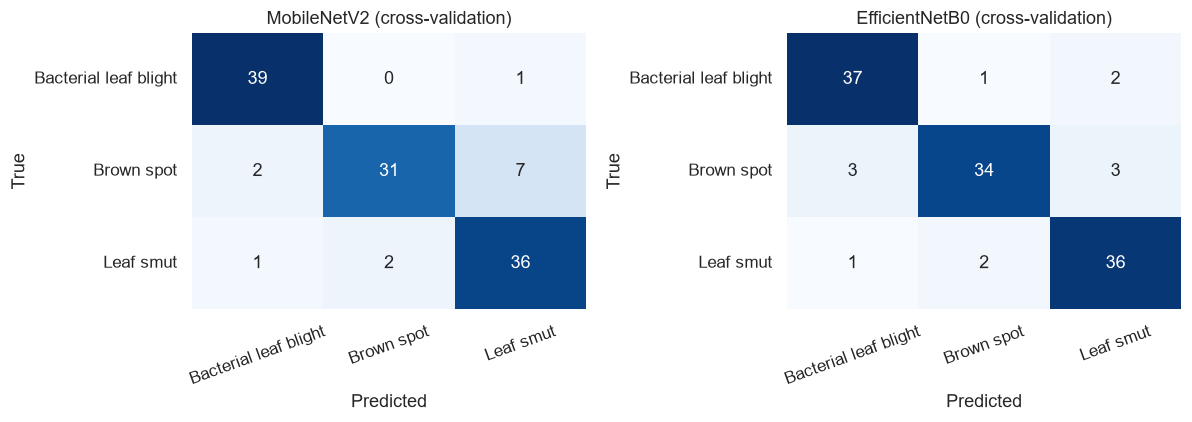

In [43]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, base_name in zip(axes, cv_preds):
    true, pred = cv_preds[base_name]
    sns.heatmap(confusion_matrix(true, pred), annot=True, fmt='d', cmap='Blues', cbar=False,
                ax=ax, xticklabels=le.classes_, yticklabels=le.classes_)
    ax.set_title(base_name + ' (cross-validation)')
    ax.set_xlabel('Predicted'); ax.set_ylabel('True')
    ax.tick_params(axis='x', rotation=20)
plt.tight_layout(); plt.show()

## Cross-Validation Results

Because the test set has only 18 images, I used 5-fold cross-validation on all 119 images. Each image was tested exactly once by a model that had not trained on it. I trained without augmentation, since it made no difference earlier.

| Model | Mean accuracy | Std across folds | Worst fold | Best fold |
|---|---|---|---|---|
| MobileNetV2 | 0.889 | 0.081 | 0.739 | 0.958 |
| EfficientNetB0 | 0.899 | 0.074 | 0.792 | 0.958 |

**What I found**
- Both models reach about 89% accuracy. MobileNetV2 got 106 of 119 images right and EfficientNetB0 got 107, so I can't say one is better.
- This is lower than the validation scores (0.91 to 0.98) and higher than the 18-image test scores (0.72 to 0.78). I trust it most because it uses every image.
- Accuracy changed a lot between folds (0.74 to 0.96), so the exact number depends on which images are tested.
- Bacterial leaf blight was the easiest class. MobileNetV2 most often confused brown spot with leaf smut (7 of 40 brown spot images).

**Limits**
- Some photos may show the same leaf, so similar images could appear in both training and test folds and make the scores slightly high.
- The folds are small (about 24 images each).

## Choice for Production

I would pick **MobileNetV2**. The two models are tied on accuracy, but MobileNetV2 is about 30% smaller (19.3 MB vs 27.9 MB) and faster per image (about 100 ms vs 170 ms or more on my CPU). Before deploying, I would retrain it on all 119 images.

# Challenges Faced

| Challenge | What I did | Result |
|---|---|---|
| Very small dataset (119 images) | Used pretrained models instead of only my own CNN | Pretrained models scored 0.91 to 0.98 on validation, against 0.87 for my CNN. |
| Wide strip images (about 3.4:1) | Resized to 448×128 and padded odd shapes with gray | Avoids squashing the leaves. I did not test the square version. |
| Tiny validation and test sets (18 images each) | Repeated runs with different seeds, then 5-fold cross-validation | Scores were unreliable: 0.98 on validation, 0.72 to 0.78 on test, 0.89 in cross-validation. |
| Strong augmentation hurt accuracy | Tested each type separately, then only gentle augmentation | All combined dropped accuracy from 0.87 to 0.70. Gentle augmentation made no real difference. |
| Brown spot and leaf smut look alike | Fine-tuned the top layers of the pretrained models | Still confused sometimes (7 of 40 brown spot images with MobileNetV2). Not solved. |

# Conclusion

I built a model that classifies rice leaf images into bacterial leaf blight, brown spot and leaf smut. In 5-fold cross-validation on all 119 images, MobileNetV2 and EfficientNetB0 both reached about 0.89 accuracy, a difference of one image, so they are tied.

I recommend **MobileNetV2** for production. It is as accurate as EfficientNetB0 here, about 30% smaller and faster per image.

**How much to trust the numbers:** my validation scores (up to 0.98) were too optimistic, because that set was used to stop training and has only 18 images. Cross-validation is the most reliable estimate, so I would expect real accuracy of around 85 to 90%.

**Limits:** the dataset is small, some photos may show the same leaf, and I did not check whether the model relies on image background.